## Search API test

- Local Index - Encoded using `Alibaba-NLP/gme-Qwen2-VL-2B-Instruct` or `sentence-transformers/all-mpnet-base-v2` on `Wiki6M_ver_1_0.jsonl`
- Bing Search API (allows local image upload) - retires on August 11th, 2025 (can't create additional instance)
- SerpAPI (does not allow local image upload)
- Serper API (does not allow) image Search
- Google Search API - too expensive


#### Local Index


In [1]:
import argparse, os, time
import faiss
import numpy as np
import pyarrow as pa
import pyarrow.feather as feather
import torch
import requests
from transformers import AutoTokenizer, AutoModel
from typing import List
from pathlib import Path

In [11]:
# Parse the user's bash log, build a summary table, and generate matplotlib line charts per dataset.
# We'll also save the table as CSV and the charts as PNGs for easy insertion into PowerPoint.
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'  # default Matplotlib font

# ----------------------
# 1) Hard-code metrics from the user's log
# ----------------------
overall = {
    "infoseek": [0.1937, 0.2522, 0.2909, 0.3175, 0.3326],
    "okvqa":    [0.2308, 0.3195, 0.3728, 0.4024, 0.4201],
    "oven":     [0.1789, 0.1890, 0.1915, 0.1923, 0.1965],
    "textvqa":  [0.1429, 0.2143, 0.2143, 0.2143, 0.2143],
}

per_qtype = {
    "infoseek": {
        "IMAGE":  [0.0886, 0.1203, 0.1519, 0.1835, 0.1962],
        "REGION": [0.0636, 0.0990, 0.1161, 0.1296, 0.1418],
        "TEXT":   [0.3248, 0.4079, 0.4665, 0.5037, 0.5218],
    },
    "okvqa": {
        "IMAGE":  [0.0667, 0.0667, 0.0667, 0.1333, 0.1333],
        "REGION": [0.1711, 0.2105, 0.2763, 0.2895, 0.3158],
        "TEXT":   [0.3205, 0.4744, 0.5256, 0.5641, 0.5769],
    },
    "oven": {
        "REGION": [0.0000, 0.0000, 0.0000, 0.0000, 0.0055],
        "TEXT":   [0.7535, 0.7958, 0.8063, 0.8099, 0.8099],
        # IMAGE not present in the provided log for this dataset
    },
    "textvqa": {
        "IMAGE":  [0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        "REGION": [0.0000, 0.1429, 0.1429, 0.1429, 0.1429],
        "TEXT":   [0.3333, 0.3333, 0.3333, 0.3333, 0.3333],
    },
}

# ----------------------
# 2) Build the table for PowerPoint (Overall recall@K)
# ----------------------
Ks = [1, 2, 3, 4, 5]
rows = []
for ds, vals in overall.items():
    row = {"Dataset": ds}
    for i, K in enumerate(Ks):
        row[f"Recall@{K}"] = vals[i]
    rows.append(row)

overall_df = pd.DataFrame(rows, columns=["Dataset"] + [f"Recall@{K}" for K in Ks])
# display_dataframe_to_user("Overall Recall@K by Dataset (copy/paste into PowerPoint)", overall_df)
# overall_df.to_csv("/mnt/data/overall_recall_table.csv", index=False)

# ----------------------
# 3) Create one clean matplotlib line chart per dataset (no subplots, default colors)
# ----------------------
figure_paths = []
for ds, qt_curves in per_qtype.items():
    plt.figure()
    for qtype in ["IMAGE", "REGION", "TEXT"]:
        if qtype in qt_curves:
            plt.plot(Ks, qt_curves[qtype], marker="o", label=qtype)
    plt.xlabel("K")
    plt.ylabel("Recall@K")
    plt.title(f"{ds}: Recall@K by QType")
    plt.legend()
    out_path = f"./dotsync-home/projects/region-mm-retrieve/plots/{ds}_recall_by_qtype.png"
    plt.savefig(out_path, dpi=200, bbox_inches="tight")
    plt.close()
    figure_paths.append(out_path)


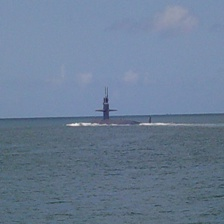

In [18]:
# Simple image display in Jupyter (absolute path)
from PIL import Image, ImageOps
from IPython.display import display

# img_path = r"/home/jeonghkim/projects/region-mm-retrieve/data/region_rag_vqa/infoseek/images/infoseek-infoseek_train_00000093/cropped_masks/mask_overlay_0.png"
img_path = r"/home/jeonghkim/projects/region-mm-retrieve/data/infoseek/images/oven_03686034.JPEG"
img = Image.open(img_path)
img = ImageOps.exif_transpose(img)  # fix orientation from EXIF (e.g., phone photos)

# Optional: shrink huge images to fit the screen (uncomment if needed)
# img.thumbnail((1600, 1600))

display(img)

In [10]:
os.listdir('dotsync-home/projects/region-mm-retrieve/plots')

['src',
 'data',
 'results',
 '__init__.py',
 '.git',
 'README.md',
 'requirements.txt',
 'plots']

In [3]:
image_paths

['/home/jeonghkim/projects/region-mm-retrieve/data/infoseek/images/oven_00003812.jpg']

#### Test search API


In [4]:
# query the local search api
search_api_url = "http://127.0.0.1:7000"
search_session = requests.Session()
timeout = 60.0
search_session.get(search_api_url.rstrip("/") + "/health", timeout=timeout)

qtype = "text"
top_k = 5
collection = "wiki10k_index"
index_name = "all-mpnet-base-v2"
pooling = "mean"

payload = {
    "qtype": qtype,
    "top_k": int(top_k),
    "collection": collection,
    "index_name": index_name,
    "pooling": pooling,
}
payload["query"] = "Jeonghwan Kim"
url = search_api_url.rstrip("/") + "/search"
resp = search_session.post(url, json=payload, timeout=timeout)
data = resp.json()

In [5]:
data

{'count': 5,
 'top_k': 5,
 'model_str': 'sentence-transformers/all-mpnet-base-v2',
 'index_dir': '/home/jeonghkim/projects/region-mm-retrieve/data/infoseek/wiki10k_index/all-mpnet-base-v2',
 'qtype': 'text',
 'pooling': 'mean',
 'hits': [{'id': 2140092,
   'row': 10724534,
   'score': 0.7498161792755127,
   'title': 'Kim Poong',
   'passage': 'Kim Jeong-hwan (; born December 12, 1978), better known by his stage name Kim Poong () is a South Korean webtoon artist.',
   'image_path': '',
   'image_url': ''},
  {'id': 12556168,
   'row': 1569521,
   'score': 0.7443488836288452,
   'title': 'Kim Jeong-hwan (volleyball)',
   'passage': 'Kim Jeong-Hwan (born ) is a South Korean male volleyball player. He is part of the South Korea men\'s national volleyball team. profile at "FIVB.org"',
   'image_path': '',
   'image_url': ''},
  {'id': 5691981,
   'row': 13784644,
   'score': 0.7398830056190491,
   'title': 'Kim Seong-hyeon (golfer)',
   'passage': 'Kim Seong-hyeon (; born 17 September 1998)

In [19]:
# query the local search api
search_api_url = "http://127.0.0.1:7000"
search_session = requests.Session()
timeout = 600.0
search_session.get(search_api_url.rstrip("/") + "/health", timeout=timeout)

qtype = "image"
top_k = 5
collection = "wiki10k_index"
pooling = "mean"

payload = {
    "qtype": qtype,
    "top_k": int(top_k),
    "collection": collection,
    "index_name": index_name,
    "pooling": pooling,
}
payload["image_paths"] = ["/home/jeonghkim/projects/region-mm-retrieve/data/infoseek/images/oven_03686034.JPEG"]
url = search_api_url.rstrip("/") + "/search"
resp = search_session.post(url, json=payload, timeout=timeout)
data = resp.json()

In [17]:
data

{'count': 5,
 'top_k': 5,
 'model_str': 'facebook/dinov3-vitb16-pretrain-lvd1689m',
 'index_dir': '/home/jeonghkim/projects/region-mm-retrieve/data/infoseek/wiki10k_index/dinov3-vitb16-pretrain-lvd1689m',
 'qtype': 'image',
 'pooling': 'mean',
 'hits': [{'id': 103193,
   'row': 28416,
   'score': 0.39380064606666565,
   'title': 'Gustave (crocodile)',
   'passage': 'Gustave is a large male Nile crocodile from Burundi. He is notorious for being a man-eater and is rumored to have killed as many as 300 people from the banks of the Ruzizi River and the northern shores of Lake Tanganyika. Though the actual number is difficult to verify, he has obtained near-mythical status and was greatly feared by people in the region.Gustave was named by Patrice Faye, a herpetologist who has been studying and investigating him since the late 1990s. Much of what is known about Gustave stems from the film "Capturing the Killer Croc", which aired in 2004 on PBS. The film documents a capture attempt and study

In [ ]:
# ---- Config ----
model_str   = "sentence-transformers/all-mpnet-base-v2"  # "Alibaba-NLP/gme-Qwen2-VL-2B-Instruct"
MODEL_NAME  = "all-mpnet-base-v2"   # must match what you used to build the index
INDEX_PATH  = "wiki10k_index"
index_dir   = Path(f"/home/jeonghkim/projects/region-mm-retrieve/data/infoseek/{INDEX_PATH}/{MODEL_NAME}")
index_path  = index_dir / "wiki6m_faiss.index"
meta_path   = index_dir / "wiki6m_meta.arrow"   # or wiki10k_meta.arrow

device = torch.device("cuda")
use_gpu     = torch.cuda.is_available()
gpu_ids     = list(range(torch.cuda.device_count()))   # e.g., [0,1,...]

# ---- Load CPU index (mmap, read-only) ---- faiss.IO_FLAG_MMAP allows memory-mapped search instead of loading the full index into RAM
wiki_index_cpu = faiss.read_index(str(index_path), faiss.IO_FLAG_MMAP | faiss.IO_FLAG_READ_ONLY)
faiss.omp_set_num_threads(8)  # good for CPU fallback

# ---- Arrow memory map for metadata ----
mm = pa.memory_map(str(meta_path), 'r')
meta_reader = pa.ipc.open_file(mm)
meta_data = meta_reader.read_all()

# Fast id → row mapping (works with your precomputation code)
ids = meta_data.column("id").to_numpy(zero_copy_only=False)
ids_dense_aligned = (ids[0] == 0) and (ids[-1] == len(ids)-1) and np.all(ids[: min(1000, len(ids))] == np.arange(min(1000, len(ids))))

if ids_dense_aligned:
    def id_to_row(i: int) -> int: return int(i)
else:
    map_path = index_dir / "id2row.argsort.int32.npy"
    if map_path.exists():
        sorted_order = np.load(map_path, mmap_mode="r")
        sorted_ids   = ids[sorted_order]
    else:
        sorted_order = np.argsort(ids).astype(np.int32)
        np.save(map_path, sorted_order)
        sorted_ids   = ids[sorted_order]
    n = len(ids)
    def id_to_row(i: int) -> int:
        pos = np.searchsorted(sorted_ids, i)
        if pos >= n or sorted_ids[pos] != i:
            raise KeyError(f"id {i} not found")
        return int(sorted_order[pos])


# ---- Move index to GPU (or all GPUs) ----
index_for_search = wiki_index_cpu
if use_gpu:
    if len(gpu_ids) == 1:
        # Single GPU
        co = faiss.GpuClonerOptions()
        co.useFloat16 = True
        co.indicesOptions = faiss.INDICES_32_BIT

        res = faiss.StandardGpuResources()
        index_for_search = faiss.index_cpu_to_gpu(res, gpu_ids[0], wiki_index_cpu, co)
    else:
        # Multi-GPU (sharded)
        mco = faiss.GpuMultipleClonerOptions()
        mco.useFloat16 = True
        mco.indicesOptions = faiss.INDICES_32_BIT
        mco.shard = True  # actually split the index across GPUs

        # Either use the convenience wrapper...
        # index_for_search = faiss.index_cpu_to_all_gpus(wiki_index_cpu, mco)

        # ...or explicitly create resources per device:
        res_list = [faiss.StandardGpuResources() for _ in gpu_ids]
        index_for_search = faiss.index_cpu_to_gpu_multiple(res_list, gpu_ids, wiki_index_cpu, mco)


In [ ]:
len(ids)

In [ ]:
# model and tokenizer load
tokenizer = AutoTokenizer.from_pretrained(model_str, trust_remote_code=True)
model = AutoModel.from_pretrained(model_str, torch_dtype=torch.float16, trust_remote_code=True).to(device).eval()

In [ ]:
#Mean Pooling - Take attention mask into account for correct averaging
def mean_pooling(model_output, attention_mask):
    token_embeddings = model_output[0] #First element of model_output contains all token embeddings
    input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
    return torch.sum(token_embeddings * input_mask_expanded, 1) / torch.clamp(input_mask_expanded.sum(1), min=1e-9)


# TODO: encode an arbitrary text query
@torch.inference_mode()
def embed_text(
        texts: List[str],
        model, model_str: str,
        max_length: int = 512) -> np.ndarray:
    """Encode & L2-normalise a single query string → (1, dim) fp32 numpy."""
    if "gme" in model_str:
        embs = model.get_text_embeddings(texts=texts)     # GME helper
    elif "sentence-transformers" in model_str:
        tok = tokenizer(texts,
                        padding=True,
                        truncation=True,
                        max_length=max_length,
                        return_tensors='pt').to(device)
        out = model(**tok)
        if "all-mpnet-base-v2" == MODEL_NAME:
            embs = mean_pooling(out, tok["attention_mask"])  # mean pooling
        else:
            embs = out.last_hidden_state[:, 0, :]  # [CLS] pooling
    embs = torch.nn.functional.normalize(embs, p=2, dim=1)
    return embs.cpu().float().numpy()

@torch.inference_mode()
def embed_image(images: List[str]) -> np.ndarray:
    """Encode & L2-normalise a single query string → (1, dim) fp32 numpy."""
    emb = model.get_image_embeddings(images=images)     # GME helper
    emb = torch.nn.functional.normalize(emb, p=2, dim=1)
    return emb.cpu().float().numpy()

@torch.inference_mode()
def embed_fused_modal(texts: List[str], images: List[str]) -> np.ndarray:
    """Encode & L2-normalise a fused modality query string → (1, dim) fp32 numpy."""
    emb = model.get_fused_embeddings(texts=texts, images=images)     # GME helper
    emb = torch.nn.functional.normalize(emb, p=2, dim=1)
    return emb.cpu().float().numpy()

def format_hit(idx: int, score: float) -> str:
    row = meta_data.slice(id_to_row(idx), 1)
    title   = row.column("title").to_pylist()[0]
    passage = row.column("passage").to_pylist()[0]
    return (f"** {score:.3f} -- {title} **\n"
            f"  {passage[:200]}\n\n")

def search(
        model,
        model_str: str,
        query: str,
        qtype: str,
        top_k: int = 5,):
    if qtype == "text":
        q = embed_text(query, model, model_str, max_length=512)
    elif qtype == "image":
        q = embed_image(query)
    elif qtype == "fused":
        pass  # TODO: Implement dual modality embedder

    scores, ids = wiki_index.search(q, top_k)
    return [
        format_hit(int(idx), float(score))
        for idx, score in zip(ids[0], scores[0])
    ]

In [ ]:
# retrieve the k nearest passages, and
query = ["mathematics is a branch of science"]
qtype = "text"
top_k = 5
hits = search(query, qtype=qtype, top_k=top_k)

# print titles, scores and snippets

In [ ]:
# print titles, scores and snippets
hits

In [ ]:
# retrieve the k nearest passages, and
query = ["/home/jeonghkim/projects/region-mm-retrieve/data/region_rag_vqa/aokvqa/images/aokvqa-24vcZcaxamEJwTD7wHYb4v/cropped_bboxes/cropped_double-decker bus_1.png"]
qtype = "image"
top_k = 10
hits = search(query, qtype=qtype, top_k=top_k)

# print titles, scores and snippets

In [ ]:
# print titles, scores and snippets
hits

### Convert beautified JSONL back into line-by-line format


In [ ]:
# Convert a beautified JSON/JSONL file back to proper JSONL (one object per line).
# Reads the uploaded file and writes a fixed version next to it for download.

import json
from pathlib import Path
from typing import Iterable, Union

INPUT = Path("/home/jeonghkim/projects/region-mm-retrieve/data/region_rag_vqa/cragmm/needs_incontext_sample.jsonl")
OUTPUT = Path("/home/jeonghkim/projects/region-mm-retrieve/data/region_rag_vqa/cragmm/needs_incontext_sample.fixed.jsonl")

def iter_top_level_json_objects(text: str) -> Iterable[str]:
    """
    Split a string containing multiple top-level JSON objects (pretty-printed)
    into individual JSON-object strings by tracking brace depth and string state.
    Ignores braces inside strings and handles escaped quotes.
    """
    objs = []
    start = None
    depth = 0
    in_str = False
    escape = False

    for i, ch in enumerate(text):
        if in_str:
            if escape:
                escape = False
            elif ch == "\\":
                escape = True
            elif ch == '"':
                in_str = False
            # stay inside string
            continue
        else:
            if ch == '"':
                in_str = True
                continue
            if ch == "{":
                if depth == 0:
                    start = i
                depth += 1
                continue
            if ch == "}":
                depth -= 1
                if depth == 0 and start is not None:
                    objs.append(text[start : i + 1])
                    start = None
                continue
            # other characters at top level are ignored

    return objs

def try_as_json_array(text: str):
    s = text.lstrip()
    if s.startswith("["):
        try:
            data = json.loads(text)
            if isinstance(data, list):
                return data
        except Exception:
            return None
    return None

def is_already_jsonl(text: str) -> bool:
    # Try to parse each non-empty line as JSON
    for line in text.splitlines():
        line = line.strip()
        if not line:
            continue
        try:
            json.loads(line)
        except Exception:
            return False
    return True

def compact_dump(obj) -> str:
    # Compact, stable ordering (as inserted), UTF-8 safe
    return json.dumps(obj, ensure_ascii=False, separators=(",", ":"))

def fix_jsonl(input_path: Union[str, Path], output_path: Union[str, Path]) -> int:
    input_path = Path(input_path)
    output_path = Path(output_path)

    txt = input_path.read_text(encoding="utf-8")

    # Case 1: JSON array
    arr = try_as_json_array(txt)
    if arr is not None:
        with output_path.open("w", encoding="utf-8") as out:
            for obj in arr:
                out.write(compact_dump(obj) + "\n")
        return len(arr)

    # Case 2: already JSONL
    if is_already_jsonl(txt):
        n = 0
        with output_path.open("w", encoding="utf-8") as out:
            for line in txt.splitlines():
                s = line.strip()
                if not s:
                    continue
                obj = json.loads(s)
                out.write(compact_dump(obj) + "\n")
                n += 1
        return n

    # Case 3: multiple pretty-printed objects concatenated
    chunks = iter_top_level_json_objects(txt)
    n = 0
    with output_path.open("w", encoding="utf-8") as out:
        for chunk in chunks:
            obj = json.loads(chunk)
            out.write(compact_dump(obj) + "\n")
            n += 1
    return n


In [ ]:
count = fix_jsonl(INPUT, OUTPUT)
print(f"Wrote {count} JSON objects to: {OUTPUT}")